# Projet d'Analyse Boursière

### Remarque: Vous êtes libre de considérer ceci comme un exercice complet ou simplement de voir la vidéo des solutions comme une revue de code pour le projet. Ce projet est conçu pour être assez stimulant car il introduira quelques nouveaux concepts par le biais de quelques astuces !

Bienvenue à votre premier projet! Ce projet est destiné à couronner la première moitié du cours, qui a principalement porté sur l'apprentissage des bibliothèques que nous utilisons dans ce cours, la deuxième moitié du cours traitera beaucoup plus des techniques financières et des plateformes de trading quantitatif.

Nous analyserons les données sur les actions de quelques compagnies automobiles du 1er janvier 2012 au 1er janvier 2017. Gardez à l'esprit que ce projet est principalement fait pour pratiquer vos compétences avec matplotlib, pandas et numpy. Ne déduisez pas des conseils de trading financier de l'analyse que nous faisons ici !

### Partie 0: Importations

**Importez les différentes bibliothèques dont vous aurez besoin - vous pouvez toujours revenir ici ou importer au fur et à mesure :)**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import yfinance as yf
import seaborn as sns



____
## Partie 1: Obtenir les données

### Action Tesla (Ticker: TSLA sur le NASDAQ)

**Note ! Tout le monde ne travaillera pas sur un ordinateur qui lui donnera un accès complet pour télécharger les informations boursières en utilisant pandas_datareader (pare-feu, permissions d'administration, etc...). Pour cette raison, le fichier csv pour Tesla est fourni dans un dossier data à l'intérieur de ce dossier. Il s'appelle Tesla_Stock.csv. N'hésitez pas à l'utiliser avec read_csv !**

**Utilisez pandas_datareader pour obtenir les informations historiques sur les actions de Tesla du 1er janvier 2012 au 1er janvier 2017.**



In [2]:
start = '2012-01-01'
end = '2017-01-01'
tesla = yf.download('TSLA', start, end, interval='1d')

display(tesla.head(5))

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA
Date,,,,,
2012-01-03,1.872000,1.966667,1.843333,1.929333,13921500
2012-01-04,1.847333,1.911333,1.833333,1.880667,9451500
2012-01-05,1.808000,1.862000,1.790000,1.850667,15082500
2012-01-06,1.794000,1.852667,1.760667,1.813333,14794500
2012-01-09,1.816667,1.832667,1.741333,1.800000,13455000


In [3]:
print(tesla)

Price           Close       High        Low       Open    Volume
Ticker           TSLA       TSLA       TSLA       TSLA      TSLA
Date                                                            
2012-01-03   1.872000   1.966667   1.843333   1.929333  13921500
2012-01-04   1.847333   1.911333   1.833333   1.880667   9451500
2012-01-05   1.808000   1.862000   1.790000   1.850667  15082500
2012-01-06   1.794000   1.852667   1.760667   1.813333  14794500
2012-01-09   1.816667   1.832667   1.741333   1.800000  13455000
...               ...        ...        ...        ...       ...
2016-12-23  14.222667  14.230000  13.847333  13.866667  70057500
2016-12-27  14.635333  14.816667  14.294667  14.325333  88735500
2016-12-28  14.649333  14.920000  14.480000  14.768667  56737500
2016-12-29  14.312000  14.613333  14.274667  14.570667  60675000
2016-12-30  14.246000  14.500000  14.112000  14.420000  69639000

[1258 rows x 5 columns]


### Autres entreprises automobiles

**Répétez les mêmes étapes pour extraire les données pour Ford et GM (General Motors)**

In [4]:
ford = yf.download('F', start, end, interval='1d')
display(ford.head(8))

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,F,F,F,F,F
Date,,,,,
2012-01-03,5.532826,5.592479,5.463231,5.468202,45709900
2012-01-04,5.617334,5.731669,5.502999,5.542767,79725200
2012-01-05,5.761495,5.781379,5.587506,5.632246,67877500
2012-01-06,5.821150,5.865890,5.726700,5.836063,59840700
2012-01-09,5.865891,5.940458,5.816180,5.880805,53981500
2012-01-10,5.865891,5.990169,5.781383,5.965313,121750600
2012-01-11,6.000111,6.054793,5.791325,5.836065,63806000
2012-01-12,6.034907,6.054792,5.910630,6.044849,48687700


In [5]:
gm = yf.download('GM', start, end, interval='1d')
display(gm.head(8))



[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,GM,GM,GM,GM,GM
Date,,,,,
2012-01-03,15.594055,15.690361,15.371813,15.431077,9321300
2012-01-04,15.668134,15.831113,15.371810,15.594052,7856700
2012-01-05,16.423754,16.512652,15.527373,15.631087,17880600
2012-01-06,16.979361,17.060850,16.475610,16.490426,18234500
2012-01-09,16.920101,17.357179,16.816388,17.186793,12084500
2012-01-10,17.216423,17.334953,16.875651,17.201606,13538300
2012-01-11,18.127623,18.253560,17.290508,17.312733,21947000
2012-01-12,18.275785,18.386907,17.601648,18.038726,16750800


## Partie 2: Visualisation des données

**Il est temps de visualiser les données.**

**Suivez et recréez les graphiques ci-dessous en suivant les instructions et les explications.**

____

**Recréez ce tracé linéaire de tous les prix à l'ouverture des différentes actions! Astuce: Pour la légende, utilisez le paramètre label et plt.legend()**

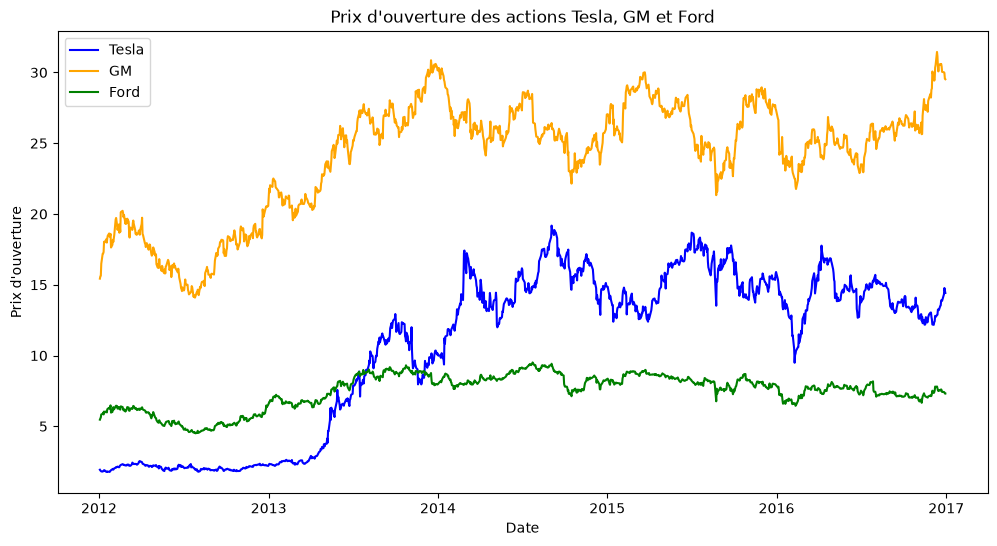

In [6]:
plt.figure(figsize=(12, 6))

plt.plot(tesla['Open'], label='Tesla',color="b")
plt.plot(gm['Open'], label='GM',color="orange")
plt.plot(ford['Open'], label='Ford',color="g")

plt.xlabel('Date')
plt.ylabel('Prix d\'ouverture')
plt.title('Prix d\'ouverture des actions Tesla, GM et Ford')

plt.legend()
plt.show()

____

**Tracez le volume des actions négociées chaque jour.**

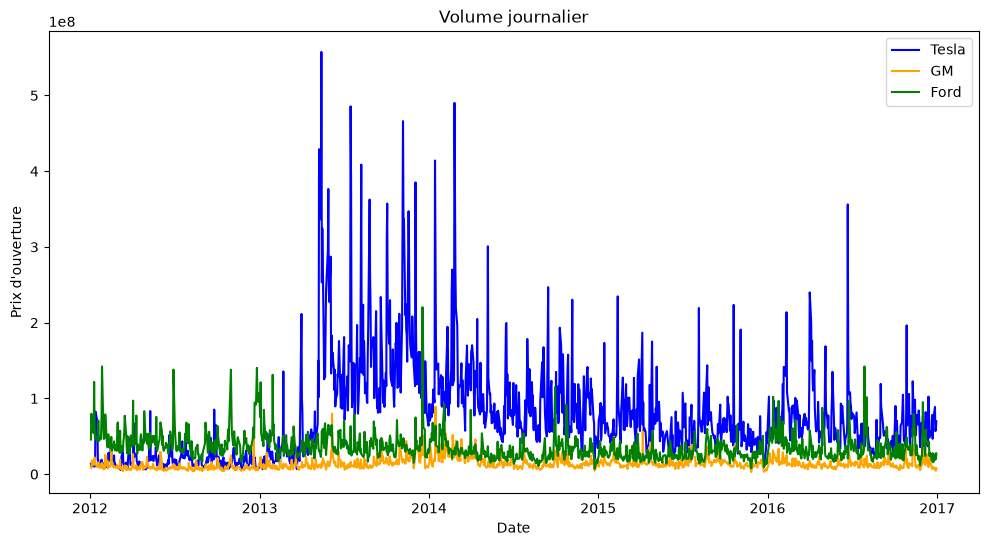

In [7]:
plt.figure(figsize=(12, 6))

plt.plot(tesla['Volume'], label='Tesla',color="b")
plt.plot(gm['Volume'], label='GM',color="orange")
plt.plot(ford['Volume'], label='Ford',color="g")

plt.xlabel('Date')
plt.ylabel('Prix d\'ouverture')
plt.title('Volume journalier')

plt.legend()
plt.show()

**Intéressant, il semble que Ford ait eu un très gros pic fin 2013. Quelle était la date de ce volume d'échange maximum pour Ford ?**

**Bonus: Que s'est-il passé ce jour-là?**

In [8]:
a=ford['Volume'].idxmax()
print(a)

Ticker
F   2013-12-18
dtype: datetime64[s]


____

*La visualisation du prix à l'ouverture des séries temporelles donne l'impression que Tesla a toujours eu beaucoup plus de valeur en tant qu'entreprise que GM et Ford. Mais pour vraiment comprendre cela, il faudrait regarder la capitalisation boursière totale de la société, et pas seulement le cours de l'action. Malheureusement, nos données actuelles n'ont pas cette information du nombre total d'unités d'actions présentes. Mais ce que nous pouvons faire comme simple calcul pour essayer de représenter l'argent total échangé serait de multiplier la colonne 'Volume' par le cours de l'action. Rappelez-vous que ce n'est pas encore la capitalisation boursière réelle, c'est juste une représentation visuelle de la quantité totale d'argent échangé en utilisant la série temporelle. (par exemple 100 unités d'actions à 10 dollars chacune contre 100 000 unités d'actions à 1 dollars chacune)*

**Créez une nouvelle colonne pour chaque dataframe appelée "Total Traded" qui est le prix d'ouverture multiplié par le volume négocié.**

In [9]:
#Pour relance en cas de NaN plus bas
tesla = yf.download('TSLA', start, end, interval='1d')
ford = yf.download('F', start, end, interval='1d')
gm = yf.download('GM', start, end, interval='1d')


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [10]:
tesla['Total Traded'] = tesla['Volume'] * tesla['Open']
gm['Total Traded'] = gm['Volume'] * gm['Open']
ford['Total Traded'] = ford['Volume'] * ford['Open']

In [11]:
print(tesla['Total Traded'])

Date
2012-01-03    2.685921e+07
2012-01-04    1.777512e+07
2012-01-05    2.791269e+07
2012-01-06    2.682736e+07
2012-01-09    2.421900e+07
                  ...     
2016-12-23    9.714640e+08
2016-12-27    1.271166e+09
2016-12-28    8.379373e+08
2016-12-29    8.840752e+08
2016-12-30    1.004194e+09
Name: Total Traded, Length: 1258, dtype: float64


In [12]:
print(gm['Total Traded'])

Date
2012-01-03    1.438377e+08
2012-01-04    1.225178e+08
2012-01-05    2.794932e+08
2012-01-06    3.006947e+08
2012-01-09    2.076938e+08
                  ...     
2016-12-23    2.809027e+08
2016-12-27    1.803455e+08
2016-12-28    2.532507e+08
2016-12-29    1.305265e+08
2016-12-30    2.257083e+08
Name: Total Traded, Length: 1258, dtype: float64


In [13]:
print(ford['Total Traded'])

Date
2012-01-03    2.499510e+08
2012-01-04    4.418982e+08
2012-01-05    3.823028e+08
2012-01-06    3.492341e+08
2012-01-09    3.174547e+08
                  ...     
2016-12-23    1.159953e+08
2016-12-27    1.445553e+08
2016-12-28    1.986002e+08
2016-12-29    1.450357e+08
2016-12-30    2.003905e+08
Name: Total Traded, Length: 1258, dtype: float64


**Tracez ce total négocié (Total Traded) par rapport à l'index de temps.**

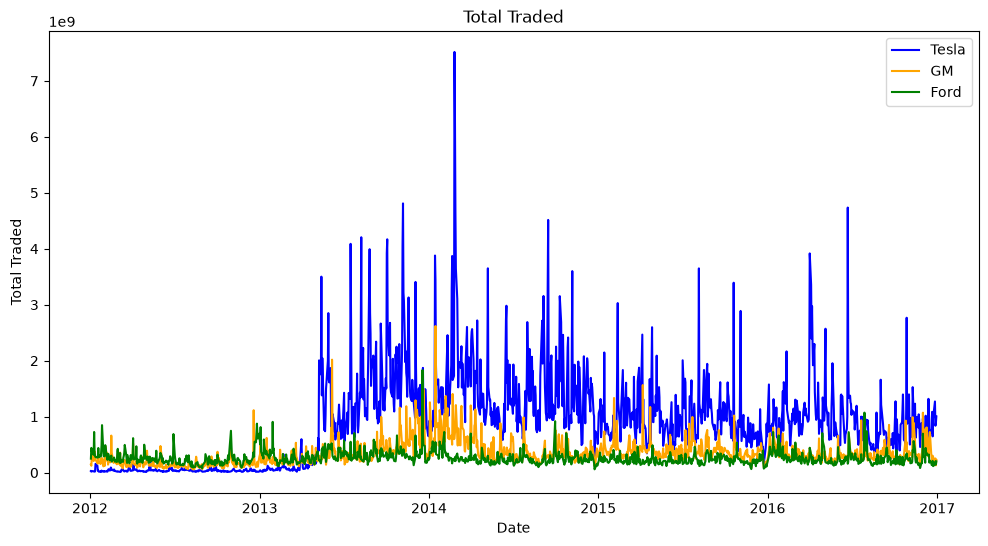

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(tesla['Total Traded'], label='Tesla',color="b")
plt.plot(gm['Total Traded'], label='GM',color="orange")
plt.plot(ford['Total Traded'], label='Ford',color="g")

plt.xlabel('Date')
plt.ylabel('Total Traded')
plt.title('Total Traded')

plt.legend()
plt.show()

**Intéressant, il semble qu'il y ait eu une énorme quantité d'argent échangé pour Tesla début 2014. Quelle date c'était et que s'est-il passé ?**

In [15]:
b=tesla['Total Traded'].idxmax()
print(b)

2014-02-25 00:00:00


____

**Entraînons-nous à tracer des moyennes glissantes ou mobiles (MA - Moving Averages). Tracez MA50 et MA200 pour GM.**

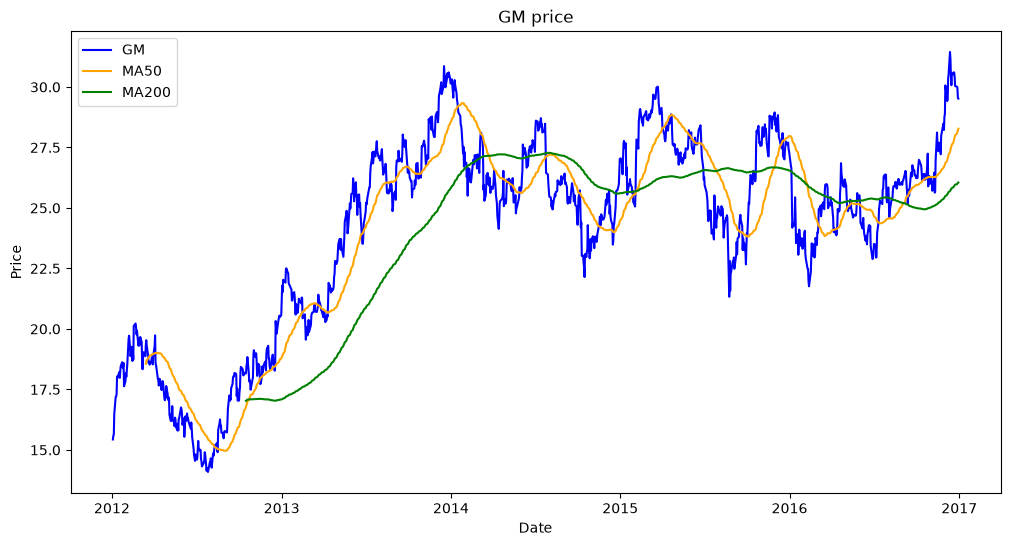

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(gm['Open'], label='GM',color="b")
plt.plot(gm['Open'].rolling(50).mean(), label='MA50',color="orange")
plt.plot(gm['Open'].rolling(200).mean(), label='MA200',color="g")

plt.title('GM price')
plt.xlabel('Date')
plt.ylabel('Price')


plt.legend()
plt.show()


______

**Enfin, voyons s'il existe une relation entre ces actions car elles sont tous liées à l'industrie automobile. Nous pouvons le voir facilement à travers un diagramme de dispersion. Importez la matrice de dispersion de pandas.plotting et utilisez-la pour créer un diagramme de dispersion du prix d'ouverture de toutes les actions. Vous devrez peut-être réorganiser les colonnes dans un nouveau dataframe unique. Vous trouverez des conseils et des informations ici: https://pandas.pydata.org/pandas-docs/stable/visualization.html#scatter-matrix-plot**

In [17]:
from pandas.plotting import scatter_matrix


In [18]:
# Fusionne les colonnes Open des 3 DataFrames par index commun (inner join)
dispersion_data = pd.concat([tesla['Open'],
    gm['Open'],
    ford['Open']],
    axis=1)

dispersion_data.columns = ['Tesla','Gen. Motors','Ford']

print(dispersion_data.head(10))



               Tesla  Gen. Motors      Ford
Date                                       
2012-01-03  1.929333    15.431077  5.468202
2012-01-04  1.880667    15.594052  5.542767
2012-01-05  1.850667    15.631087  5.632246
2012-01-06  1.813333    16.490426  5.836063
2012-01-09  1.800000    17.186793  5.880805
2012-01-10  1.829333    17.201606  5.965313
2012-01-11  1.841333    17.312733  5.836065
2012-01-12  1.898667    18.038726  6.044849
2012-01-13  1.893333    17.979461  5.970285
2012-01-17  1.774667    18.223928  6.064734


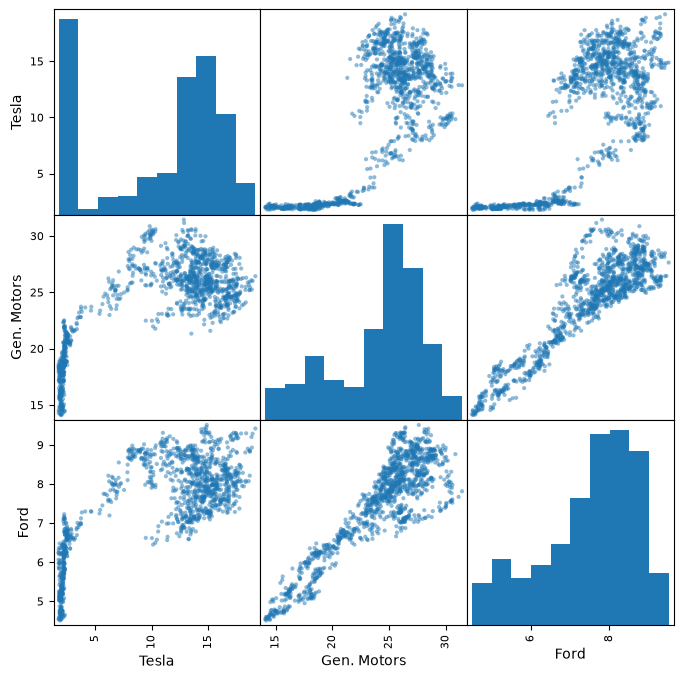

In [19]:
scatter_matrix(dispersion_data, alpha=0.5, figsize=(8, 8), diagonal='hist')
plt.show()


_____
### Bonus: Tâche de visualisation ! (C'est difficile !)
**Créons maintenant un graphique en chandelier! Regardez la vidéo si vous ne parvenez pas à recréer cette visualisation, il y a plusieurs étapes à suivre! Référez-vous à la vidéo pour comprendre comment interpréter et lire ce graphique. Conseils: https://matplotlib.org/examples/pylab_examples/finance_demo.html**

**Créer un graphique de chandeliers pour Ford en janvier 2012 (trop de dates, ce ne sera pas idéal pour un graphique en chandelier)**

In [20]:
# Code ici

____
# Partie 3: Analyse financière de base

Il est maintenant temps de se concentrer sur quelques calculs financiers clés. Cela vous servira de transition vers la deuxième moitié du cours. Vous n'avez qu'à suivre les instructions, il s'agira principalement d'un exercice de conversion d'une équation ou d'un concept mathématique en code à l'aide de python et pandas, ce que nous ferons souvent lorsque nous travaillerons avec des données quantitatives! Si vous vous sentez perdu dans cette section, ne vous inquiétez pas! Allez simplement au notebook (ou vidéo) sur les solutions et traitez-la comme une revue de code, utilisez le style d'apprentissage qui vous convient le mieux!

Commençons !
____

## Rendement quotidien en pourcentage
Nous commencerons par calculer la rendement quotidienne en pourcentage. Le rendement (en %) est défini par la formule suivante :

$ r_t = \frac{p_t}{p_{t-1}} -1$

Cela définit r_t (rendement à l'instant t) comme étant égal au prix à l'instant t divisé par le prix à l'instant t-1 (la veille) moins 1. En gros, cela vous informe simplement de votre pourcentage de gain (ou de perte) si vous avez acheté l'action le jour et l'avez ensuite vendue le lendemain. Bien que cela ne soit pas nécessairement utile pour tenter de prédire les valeurs futures du titre, c'est très utile pour analyser la volatilité du titre. Si les rendements quotidiens ont une large distribution, le titre est plus volatil d'un jour à l'autre. Calculons les pourcentages de rendement, puis traçons un histogramme et décidons quel titre est le plus stable!

**Créez une nouvelle colonne pour chaque dataframe appelée 'returns'. Cette colonne sera calculée à partir de la colonne de prix à la fermeture'Close'. Il y a deux façons de faire cela, soit un simple calcul en utilisant la méthode .shift() qui suit la formule ci-dessus, ou vous pouvez aussi utiliser la méthode pct_change intégrée à pandas.**

#### Méthode 1: en utilisant shift


In [21]:
#Pour relance en cas de NaN plus bas
tesla = yf.download('TSLA', start, end, interval='1d')
ford = yf.download('F', start, end, interval='1d')
gm = yf.download('GM', start, end, interval='1d')

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [22]:
tesla['returns'] = (tesla['Close'].shift(-1) / tesla['Close']) - 1
print(tesla['returns'].dropna().tail(8))

Date
2016-12-19    0.029892
2016-12-20   -0.005221
2016-12-21    0.003611
2016-12-22    0.023459
2016-12-23    0.029015
2016-12-27    0.000957
2016-12-28   -0.023027
2016-12-29   -0.004612
Name: returns, dtype: float64


In [23]:
gm['returns'] = (gm['Close'].shift(-1) / gm['Close']) - 1
print(gm['returns'].dropna().tail(8))

Date
2016-12-19    0.005769
2016-12-20   -0.005190
2016-12-21   -0.020044
2016-12-22    0.000000
2016-12-23   -0.004203
2016-12-27   -0.010974
2016-12-28   -0.000285
2016-12-29   -0.008537
Name: returns, dtype: float64


In [24]:
ford['returns'] = (ford['Close'].shift(-1) / ford['Close']) - 1
print(ford['returns'].dropna().tail(8))

Date
2016-12-19    0.009479
2016-12-20   -0.010955
2016-12-21   -0.018988
2016-12-22    0.004839
2016-12-23   -0.005618
2016-12-27   -0.011299
2016-12-28   -0.001633
2016-12-29   -0.008176
Name: returns, dtype: float64


#### Méthode 2: en utilisant pct_changes

In [25]:
tesla['returns2'] = tesla['Close'].pct_change()
print(tesla['returns2'].dropna().tail(8))

Date
2016-12-20    0.029892
2016-12-21   -0.005221
2016-12-22    0.003611
2016-12-23    0.023459
2016-12-27    0.029015
2016-12-28    0.000957
2016-12-29   -0.023027
2016-12-30   -0.004612
Name: returns2, dtype: float64


In [26]:
gm['returns2'] = gm['Close'].pct_change()
print(gm['returns2'].dropna().tail(8))

Date
2016-12-20    0.005769
2016-12-21   -0.005190
2016-12-22   -0.020044
2016-12-23    0.000000
2016-12-27   -0.004203
2016-12-28   -0.010974
2016-12-29   -0.000285
2016-12-30   -0.008537
Name: returns2, dtype: float64


In [27]:
ford['returns2'] = ford['Close'].pct_change()
print(ford['returns2'].dropna().tail(8))

Date
2016-12-20    0.009479
2016-12-21   -0.010955
2016-12-22   -0.018988
2016-12-23    0.004839
2016-12-27   -0.005618
2016-12-28   -0.011299
2016-12-29   -0.001633
2016-12-30   -0.008176
Name: returns2, dtype: float64


**Maintenant, tracez un histogramme des rendements de chaque entreprise. Soit vous les faites séparément, soit vous les empilez les uns sur les autres. Quelle est l'action la plus "volatile"? (selon la variance des rendements quotidiens, nous discuterons de la volatilité de façon beaucoup plus détaillée dans les prochaines sections).**

Tesla

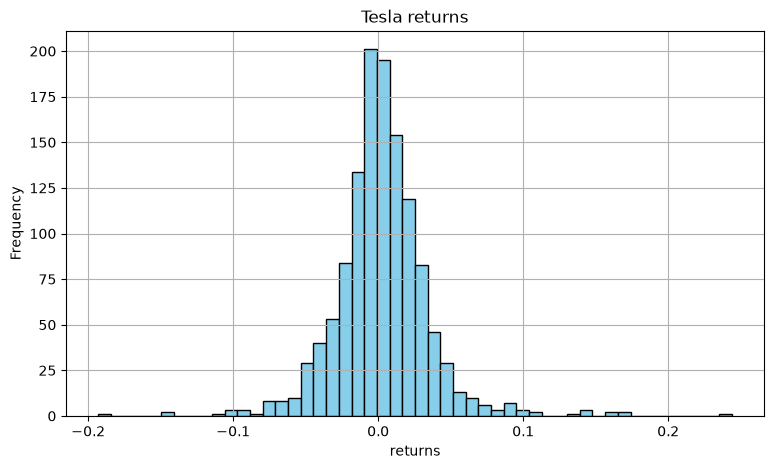

In [28]:
plt.figure(figsize=(9, 5))

plt.hist(tesla['returns'].dropna(), bins=50, label='Tesla',color="skyblue",edgecolor='black')

plt.title('Tesla returns')
plt.ylabel('Frequency')
plt.xlabel('returns')
plt.grid(True)


plt.show()

GM

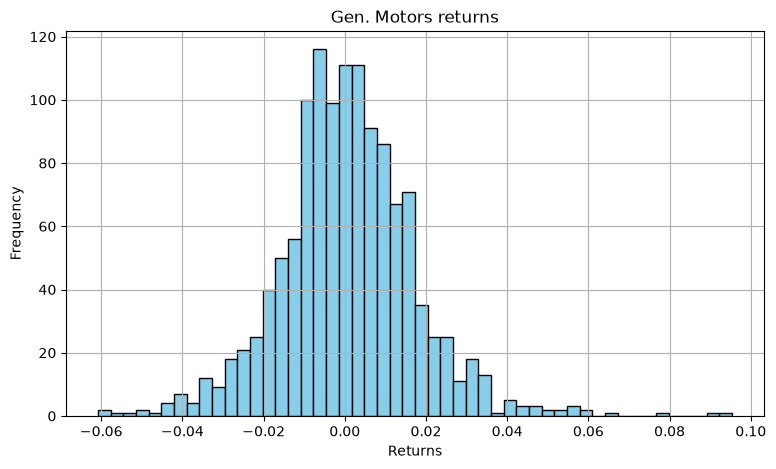

In [29]:
plt.figure(figsize=(9, 5))

plt.hist(gm['returns'].dropna(), bins=50, label='gm',color="skyblue",edgecolor='black')

plt.title('Gen. Motors returns')
plt.ylabel('Frequency')
plt.xlabel('Returns')
plt.grid(True)


plt.show()

Ford

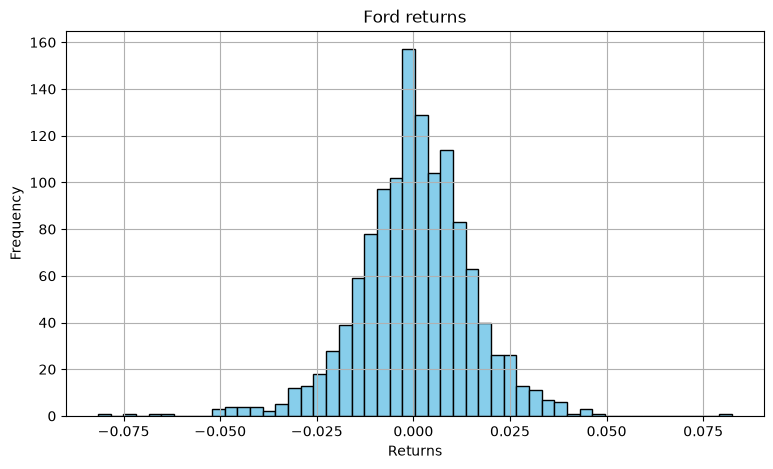

In [30]:
plt.figure(figsize=(9, 5))

plt.hist(ford['returns'].dropna(), bins=50, label='ford',color="skyblue",edgecolor='black')

plt.title('Ford returns')
plt.ylabel('Frequency')
plt.xlabel('Returns')
plt.grid(True)


plt.show()

Combiné

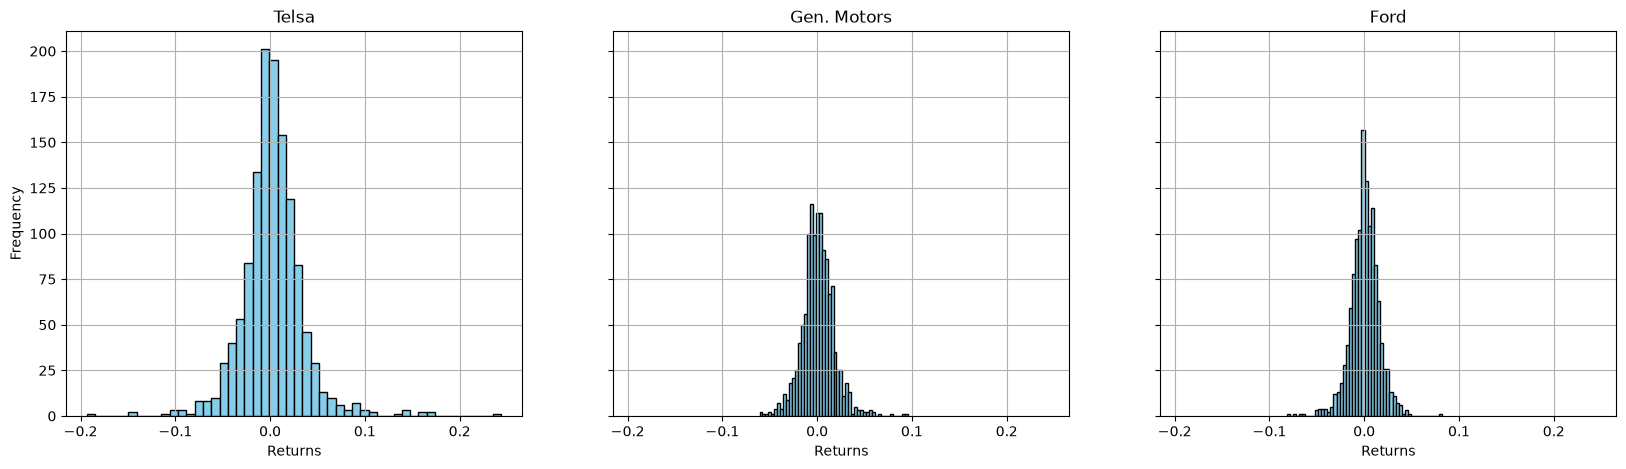

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)  # 1 ligne, 3 colonnes

axes[0].hist(tesla['returns'].dropna(), bins=50, label='Tesla',color="skyblue",edgecolor='black' )
axes[0].set_title('Telsa')
axes[0].set_xlabel('Returns')
axes[0].set_ylabel('Frequency')
axes[0].grid(True)

axes[1].hist(gm['returns'].dropna(), bins=50, label='Gen. Motors',color="skyblue",edgecolor='black' )
axes[1].set_title('Gen. Motors')
axes[1].set_xlabel('Returns')
axes[1].grid(True)

axes[2].hist(ford['returns'].dropna(), bins=50, label='Ford',color="skyblue",edgecolor='black' )
axes[2].set_title('Ford')
axes[2].set_xlabel('Returns')
axes[2].grid(True)

plt.show()


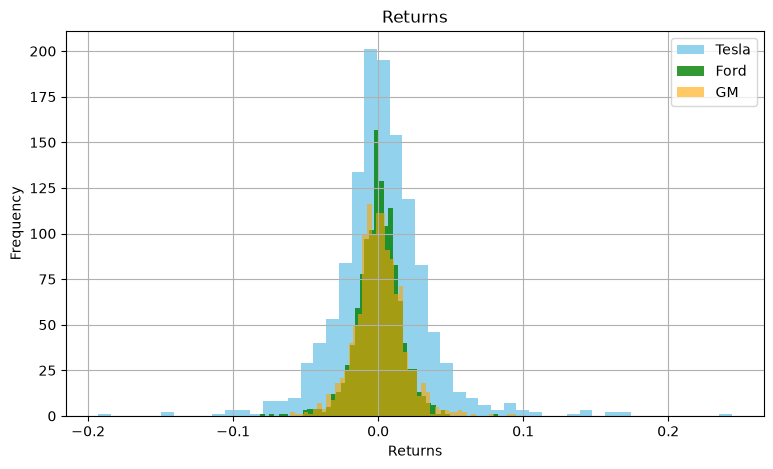

In [32]:
plt.figure(figsize=(9, 5))

plt.hist(tesla['returns'].dropna(), bins=50, label='Tesla',color="skyblue", alpha=0.9)
plt.hist(ford['returns'].dropna(), bins=50, label='Ford',color="g", alpha=0.8)
plt.hist(gm['returns'].dropna(), bins=50, label='GM',color="orange", alpha=0.6)

plt.title('Returns')
plt.xlabel('Returns')
plt.ylabel('Frequency')
plt.grid(True)
plt.legend()

plt.show()

**Essayez aussi de tracer un KDE au lieu dun 'histogrammes pour avoir un autre point de vue. Quelle action a le tracé le plus large?**

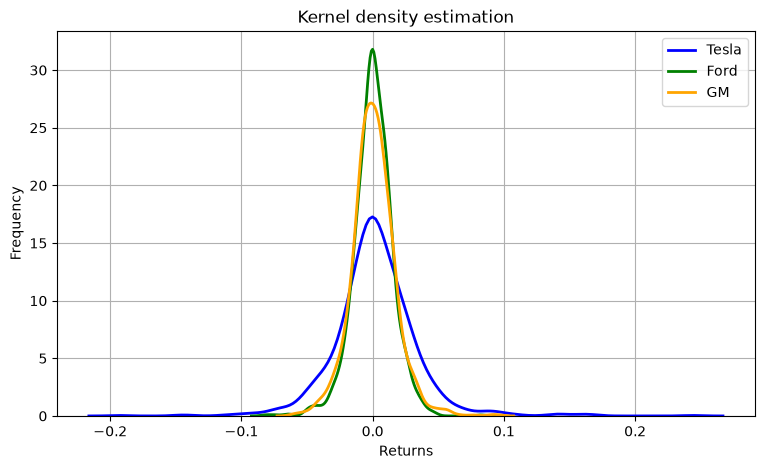

In [33]:
plt.figure(figsize=(9, 5))

sns.kdeplot(tesla['returns'].dropna(), label='Tesla',color="b", linewidth=2)
sns.kdeplot(ford['returns'].dropna(), label='Ford',color="g", linewidth=2)
sns.kdeplot(gm['returns'].dropna(), label='GM',color="orange", linewidth=2)

plt.title('Kernel density estimation')
plt.xlabel('Returns')
plt.ylabel('Frequency')
plt.grid(True)
plt.legend()

plt.show()

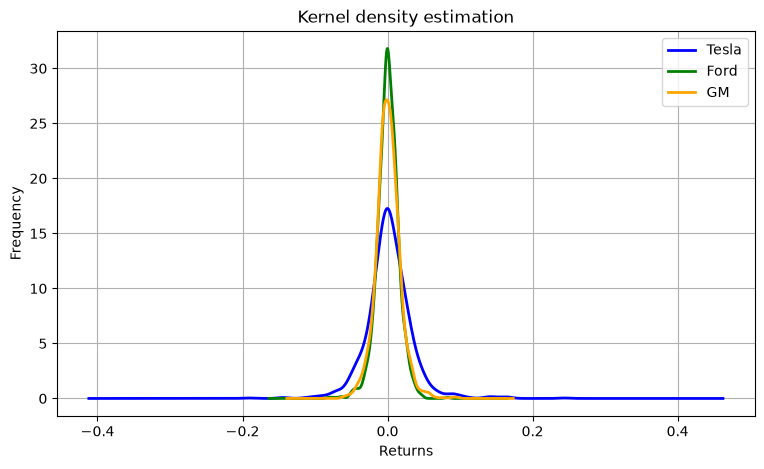

In [34]:
plt.figure(figsize=(9, 5))

tesla['returns'].dropna().plot.kde(label='Tesla',color="b", linewidth=2)
ford['returns'].dropna().plot.kde(label='Ford',color="g", linewidth=2)
gm['returns'].dropna().plot.kde(label='GM',color="orange", linewidth=2)

plt.title('Kernel density estimation')
plt.xlabel('Returns')
plt.ylabel('Frequency')
plt.grid(True)
plt.legend()

plt.show()

**Essayez aussi de créer des diagrammes en boîtes comparant les rendements.**

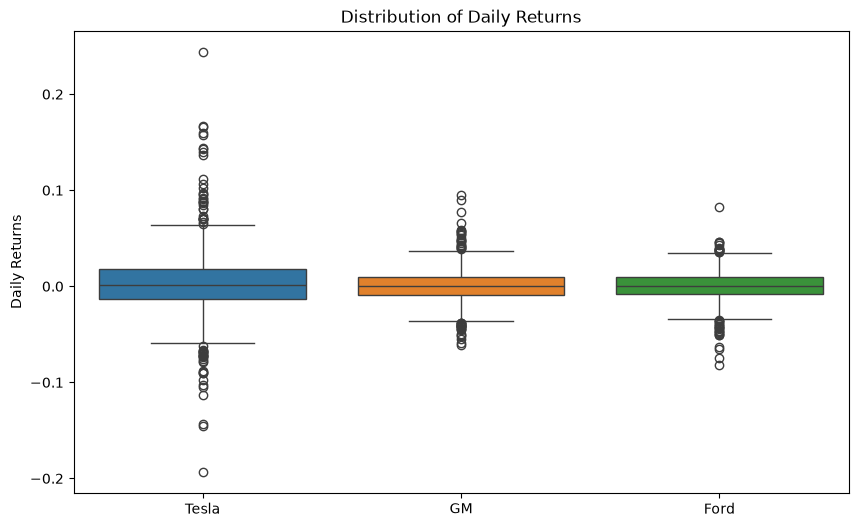

In [35]:
returns_df = pd.concat([tesla['returns'], gm['returns'], ford['returns']], axis=1)
returns_df.columns = ['Tesla', 'GM', 'Ford']

plt.figure(figsize=(10, 6))
sns.boxplot(data=returns_df)
plt.title('Distribution of Daily Returns')
plt.ylabel('Daily Returns')
plt.show()

<Figure size 1000x600 with 0 Axes>

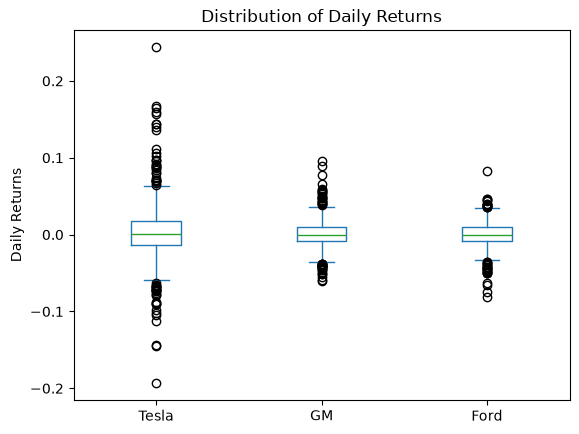

In [36]:
returns_df = pd.concat([tesla['returns'], gm['returns'], ford['returns']], axis=1)
returns_df.columns = ['Tesla', 'GM', 'Ford']

plt.figure(figsize=(10, 6))
returns_df[['Tesla', 'GM', 'Ford']].plot.box()

plt.title('Distribution of Daily Returns')
plt.ylabel('Daily Returns')

plt.show()

## Comparaison des rendements quotidiens entre les actions

**Créez un graphique matriciel de dispersion pour voir la corrélation entre les rendements quotidiens de chaque titre. Cela permet de répondre à la question de savoir dans quelle mesure les sociétés automobiles sont liées entre elles. Le marché considère-t-il Tesla comme une entreprise de technologie plutôt que comme une entreprise automobile ?**

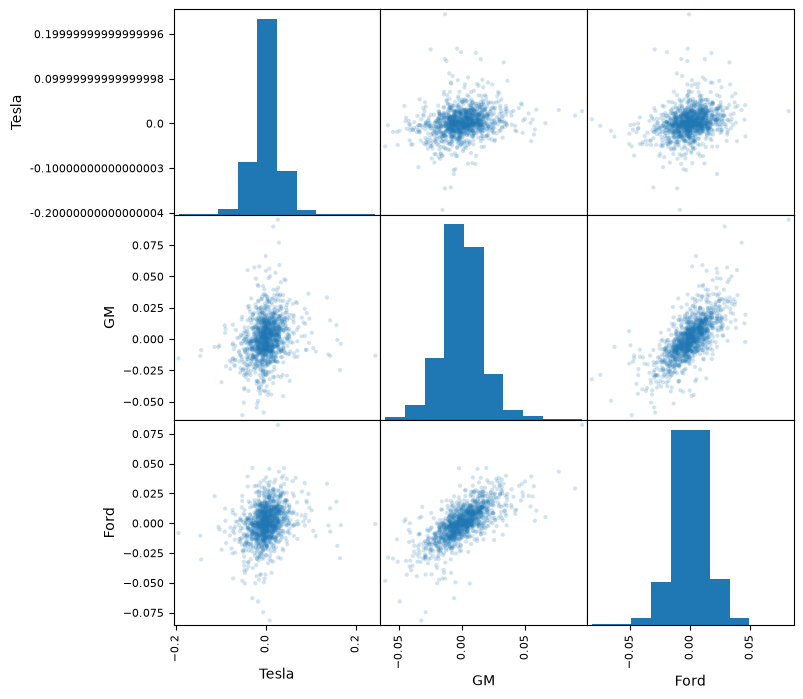

In [37]:
scatter_matrix(returns_df, alpha=0.2, figsize=(8, 8), diagonal='hist')
plt.show()

**Il semble que Ford et GM aient une sorte de relation, traçons juste ces deux-là dans un diagramme de dispersion pour voir cela de plus près !**

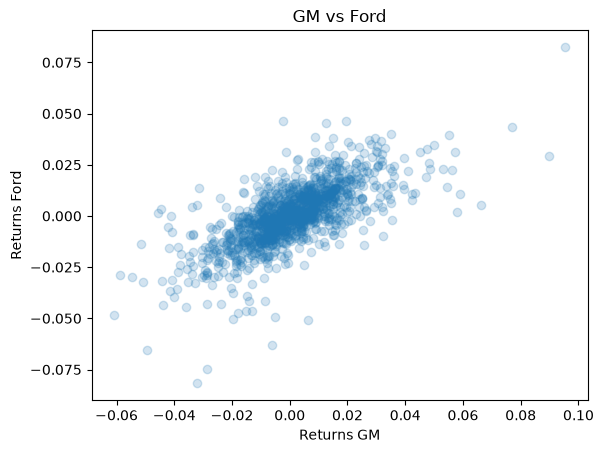

In [38]:
plt.scatter(x=returns_df['GM'], y=returns_df['Ford'], alpha=0.2)

plt.xlabel('Returns GM')
plt.ylabel('Returns Ford')
plt.title('GM vs Ford')

plt.show()

____
## Rendements quotidiens cumulatifs

Super ! Nous pouvons maintenant voir quel titre a eu le plus grand écart de rendement quotidien (vous auriez dû vous rendre compte que c'était Tesla, notre graphique original du cours de l'action aurait dû aussi le montrer).

Avec les rendements cumulatifs quotidiens, la question à laquelle nous essayons de répondre est la suivante: si j'avais investi 1$ dans l'entreprise au début de la série temporelle, combien vaudrait-elle aujourd'hui? Cette question est différente de celle du prix de l'action à la journée courante, car elle tiendra compte des rendements quotidiens. N'oubliez pas que notre simple calcul ici ne tiendra pas compte des actions qui redonnent un dividende. Examinons quelques exemples simples:

Disons qu'il y a une action "ABC" qui est activement négociée en bourse. ABC a les prix suivants correspondant aux dates indiquées:

    Date                        Prix
    01/01/2018                   10
    01/02/2018                   15
    01/03/2018                   20
    01/04/2018                   25

**Rendement quotidien**: Le rendement quotidien est le profit ou perte réalisé par l'action par rapport à la veille. (C'est ce qu'on vient de calculer ci-dessus). Une valeur supérieure à 1 indique un profit, de même qu'une valeur inférieure à 1 indique une perte. Il est également exprimé en pourcentage pour mieux transmettre l'information. (Exprimé en pourcentage, si la valeur est supérieure à 0, le titre vous a donné un profit, sinon une perte). Ainsi, pour l'exemple ci-dessus, les rendements quotidiens seraient

    Date                 Rendement quotidien      %Rendement quotidien
    01/01/2018               10/10 =  1                      -   
    01/02/2018               15/10 =  3/2                    50%
    01/03/2018               20/15 =  4/3                    33%
    01/04/2018               25/20 =  5/4                    20%

**Rendement Cumulé**: Bien que les rendements quotidiens soient utiles, ils ne donnent pas à l'investisseur un aperçu immédiat des gains qu'il a réalisés jusqu'à présent, surtout si le titre est très volatil. Le rendement cumulatif est calculé par rapport au jour où l'investissement est effectué.  Si le rendement cumulatif est supérieur à 1, vous faites des profits, sinon vous êtes en perte. Donc, pour l'exemple ci-dessus, les gains cumulatifs sont les suivants:

    Date                Rendement cumulé         %rendement cumulé
    01/01/2018              10/10 =  1               100 %   
    01/02/2018              15/10 =  3/2             150 %
    01/03/2018              20/10 =  2               200 %
    01/04/2018              25/10 =  5/2             250 %

La formule pour un rendement quotidien cumulatif est la suivante :

$ i_i = (1+r_t) * i_{t-1} $

Ici, nous pouvons voir que nous ne faisons que multiplier notre investissement précédent à i à t-1 par 1+notre pourcentage de rendement. Pandas rend cela très simple à calculer avec sa méthode cumprod(). En utilisant quelque chose de la manière suivante :

    df[daily_cumulative_return] = (1 + df[pct_daily_return]).cumprod()
    

**Créez une colonne de rendement quotidien cumulatif (cumulative daily return) pour le dataframe de chaque société automobile.**

In [39]:
tesla['cumulative_return'] = (1 + tesla['returns']).cumprod()
print(tesla['cumulative_return'].head(8))

Date
2012-01-03    0.986823
2012-01-04    0.965812
2012-01-05    0.958333
2012-01-06    0.970442
2012-01-09    0.983618
2012-01-10    1.005342
2012-01-11    1.006054
2012-01-12    0.811610
Name: cumulative_return, dtype: float64


In [40]:
gm['cumulative_return'] = (1 + gm['returns']).cumprod()
print(gm['cumulative_return'].head(8))

Date
2012-01-03    1.004750
2012-01-04    1.053206
2012-01-05    1.088835
2012-01-06    1.085035
2012-01-09    1.104038
2012-01-10    1.162470
2012-01-11    1.171971
2012-01-12    1.153919
Name: cumulative_return, dtype: float64


In [41]:
ford['cumulative_return'] = (1 + ford['returns']).cumprod()
print(ford['cumulative_return'].head(8))

Date
2012-01-03    1.015274
2012-01-04    1.041329
2012-01-05    1.052111
2012-01-06    1.060198
2012-01-09    1.060198
2012-01-10    1.084457
2012-01-11    1.090746
2012-01-12    1.081761
Name: cumulative_return, dtype: float64


In [42]:
display(tesla.head(5))
display(gm.head(5))
display(ford.head(5))

Price,Close,High,Low,Open,Volume,returns,returns2,cumulative_return
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA,,,
Date,,,,,,,,
2012-01-03,1.872000,1.966667,1.843333,1.929333,13921500,-0.013177,NaN,0.986823
2012-01-04,1.847333,1.911333,1.833333,1.880667,9451500,-0.021292,-0.013177,0.965812
2012-01-05,1.808000,1.862000,1.790000,1.850667,15082500,-0.007743,-0.021292,0.958333
2012-01-06,1.794000,1.852667,1.760667,1.813333,14794500,0.012635,-0.007743,0.970442
2012-01-09,1.816667,1.832667,1.741333,1.800000,13455000,0.013578,0.012635,0.983618


Price,Close,High,Low,Open,Volume,returns,returns2,cumulative_return
Ticker,GM,GM,GM,GM,GM,,,
Date,,,,,,,,
2012-01-03,15.594055,15.690361,15.371813,15.431077,9321300,0.004750,NaN,1.004750
2012-01-04,15.668134,15.831113,15.371810,15.594052,7856700,0.048227,0.004750,1.053206
2012-01-05,16.423754,16.512652,15.527373,15.631087,17880600,0.033829,0.048227,1.088835
2012-01-06,16.979361,17.060850,16.475610,16.490426,18234500,-0.003490,0.033829,1.085035
2012-01-09,16.920101,17.357179,16.816388,17.186793,12084500,0.017513,-0.003490,1.104038


Price,Close,High,Low,Open,Volume,returns,returns2,cumulative_return
Ticker,F,F,F,F,F,,,
Date,,,,,,,,
2012-01-03,5.532826,5.592479,5.463231,5.468202,45709900,0.015274,NaN,1.015274
2012-01-04,5.617334,5.731669,5.502999,5.542767,79725200,0.025664,0.015274,1.041329
2012-01-05,5.761495,5.781379,5.587506,5.632246,67877500,0.010354,0.025664,1.052111
2012-01-06,5.821150,5.865890,5.726700,5.836063,59840700,0.007686,0.010354,1.060198
2012-01-09,5.865891,5.940458,5.816180,5.880805,53981500,0.000000,0.007686,1.060198


**Tracez maintenant les colonnes de rendement cumulatif en fonction de l'index de la série temporelle. Quel titre a affiché le rendement le plus élevé pour un dollar investi? Lequel a affiché le rendement le plus faible?**

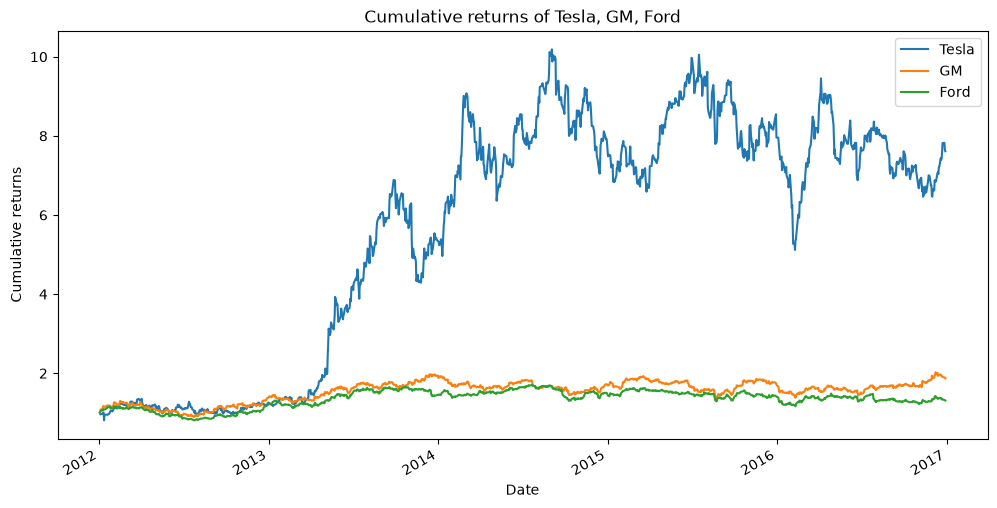

In [43]:
plt.figure(figsize=(12,6))

tesla['cumulative_return'].plot.line(label='Tesla')
gm['cumulative_return'].plot.line(label='GM')
ford['cumulative_return'].plot.line(label='Ford')

plt.title('Cumulative returns of Tesla, GM, Ford')
plt.xlabel('Date')
plt.ylabel('Cumulative returns')
plt.legend()

plt.show()


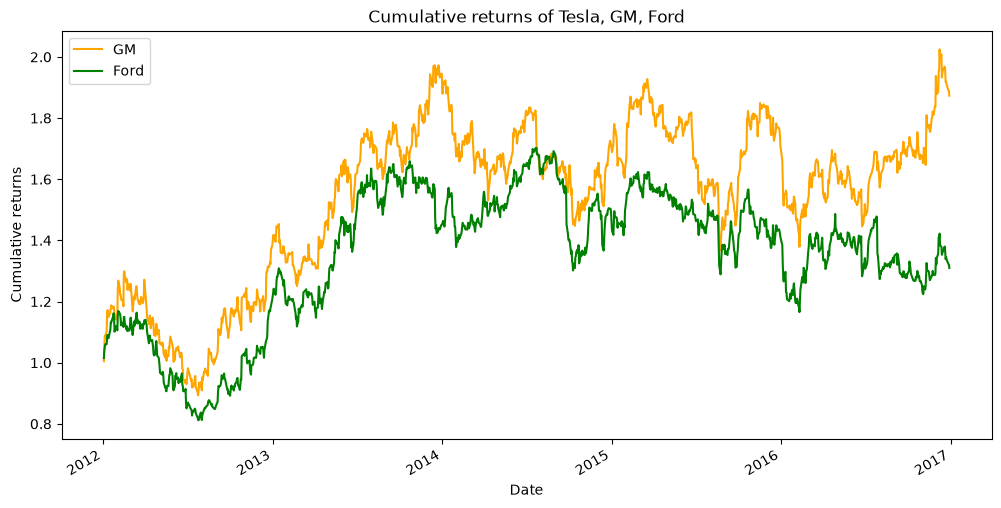

In [44]:
plt.figure(figsize=(12,6))

gm['cumulative_return'].plot.line(label='GM',  color='orange')
ford['cumulative_return'].plot.line(label='Ford', color='g')

plt.title('Cumulative returns of Tesla, GM, Ford')
plt.xlabel('Date')
plt.ylabel('Cumulative returns')
plt.legend()

plt.show()

# Bon travail!

Voilà pour l'analyse de base, qui conclut cette moitié du cours, beaucoup plus axée sur l'apprentissage des outils du métier. La deuxième moitié du cours est celle où nous nous plongerons vraiment dans les fonctionnalités conçues pour les séries temporelles, l'analyse quantitative, le trading algorithmique, et bien plus encore!